# P48 – Is This Water Safe to Drink?
**Name:** SAHIL SHAIKH
**Roll No.:** D55
**Enrollment No.:** 24004501210404
**Division:** E

**Problem:** Predict whether water is potable from pH, hardness, solids, chloramines, sulfate, conductivity, organic carbon, trihalomethanes and turbidity.
**Dataset:** https://www.kaggle.com/datasets/adityakadiwal/water-potability
**Target (Y):** Potability (0/1)
**Model:** Support Vector Machine (SVM)
**Main metric:** Precision for 'safe' (calling unsafe water safe is dangerous)

## Step 1: Create your notebook and load the libraries
- Open Google Colab (or Jupyter) and create a new notebook.
- Rename it as RollNo_P48_Name.ipynb (example: H35_P48_Riya.ipynb).
- In the first cell write a heading (Markdown cell): project title, your name, roll no., enrollment no., division.
- Run the code cell below. If you see 'All libraries loaded!' you are ready.

In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, RocCurveDisplay)
from sklearn.svm import SVC
import warnings; warnings.filterwarnings("ignore")
print("All libraries loaded!")

All libraries loaded!


## Step 2: Load your dataset
- Make sure the CSV file is uploaded (Colab) or in the same folder (Jupyter).
- Run the code below. You should see the number of rows and columns, and the first 5 rows.

In [3]:
df = pd.read_csv("water_potability.csv")
print(df.shape)      # (rows, columns)
df.head()
df

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1


## Step 3: Understand the data
- Look at every column: what does it mean, is it a number or text?
- Check missing values and the target classes.
- Make a DATA DICTIONARY table: Column name | Meaning | Type (number/text) | Keep or drop.

In [4]:

# Step 3: Understand the Data

import pandas as pd

# Create Data Dictionary
data_dictionary = pd.DataFrame({
    "Column name": [
        "ph",
        "Hardness",
        "Solids",
        "Chloramines",
        "Sulfate",
        "Conductivity",
        "Organic_carbon",
        "Trihalomethanes",
        "Turbidity",
        "Potability"
    ],
    "Meaning": [
        "Measures water acidity or alkalinity",
        "Measures water hardness",
        "Total dissolved solids in water",
        "Amount of chloramines in water",
        "Sulfate concentration in water",
        "Ability of water to conduct electricity",
        "Organic carbon concentration in water",
        "Trihalomethanes concentration in water",
        "Measures cloudiness of water",
        "Water potability: 0 = Not potable, 1 = Potable"
    ],
    "Type (number/text)": [
        "Number", "Number", "Number", "Number", "Number",
        "Number", "Number", "Number", "Number", "Number (0/1)"
    ],
    "Keep or Drop": [
        "Keep", "Keep", "Keep", "Keep", "Keep",
        "Keep", "Keep", "Keep", "Keep", "Keep (Target)"
    ]
})

print("DATA DICTIONARY")
display(data_dictionary)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check target class counts
print("\nTarget Class Counts:")
print(df["Potability"].value_counts())

# Observations
print("\nWhat I Noticed:")
print("1. The dataset contains 9 numerical input features and 1 target column, Potability.")
print("2. The ph, Sulfate, and Trihalomethanes columns contain missing values. "
      "The target classes are slightly imbalanced.")


DATA DICTIONARY


,Column name,Meaning,Type (number/text),Keep or Drop
0,ph,Measures water acidity or alkalinity,Number,Keep
1,Hardness,Measures water hardness,Number,Keep
2,Solids,Total dissolved solids in water,Number,Keep
3,Chloramines,Amount of chloramines in water,Number,Keep
4,Sulfate,Sulfate concentration in water,Number,Keep
5,Conductivity,Ability of water to conduct electricity,Number,Keep
6,Organic_carbon,Organic carbon concentration in water,Number,Keep
7,Trihalomethanes,Trihalomethanes concentration in water,Number,Keep
8,Turbidity,Measures cloudiness of water,Number,Keep
9,Potability,"Water potability: 0 = Not potable, 1 = Potable",Number (0/1),Keep (Target)



Missing Values:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

Target Class Counts:
Potability
0    1998
1    1278
Name: count, dtype: int64

What I Noticed:
1. The dataset contains 9 numerical input features and 1 target column, Potability.
2. The ph, Sulfate, and Trihalomethanes columns contain missing values. The target classes are slightly imbalanced.


## Step 4: Prepare the target column (Y)
- Your target (what the model predicts) is: Potability (0/1).
- The target already exists in the data. Just check how many rows each class has.
- If one class is much bigger than others, the data is IMBALANCED. Write this down: it affects which metric you trust.

In [6]:

# Step 4: Prepare the Target Column (Y)

TARGET = "Potability"

# Count rows in each class
print("Class Counts:")
print(df[TARGET].value_counts())

# Display class percentages
print("\nClass Percentages:")
print(df[TARGET].value_counts(normalize=True) * 100)

# Check whether the dataset is balanced or imbalanced
class_counts = df[TARGET].value_counts()

if class_counts.max() / class_counts.min() < 1.5:
    print("\nThe dataset is relatively balanced.")
else:
    print("\nThe dataset is imbalanced.")

# Display target classes and their counts
print("\nTarget Classes:")
for cls, count in class_counts.items():
    print(f"Class {cls}: {count} rows")


Class Counts:
Potability
0    1998
1    1278
Name: count, dtype: int64

Class Percentages:
Potability
0    60.989011
1    39.010989
Name: proportion, dtype: float64

The dataset is imbalanced.

Target Classes:
Class 0: 1998 rows
Class 1: 1278 rows


## Step 5: Clean the data
- Remove duplicate rows.
- Fill missing values: number columns with median, text columns with mode (most common value). Or drop a column if most of it is empty.
- Drop ID / name columns and any column that gives away the answer (leakage).
- Special note for YOUR dataset: ph, Sulfate and Trihalomethanes have many missing values: compare mean vs median imputation. Features have weak correlation with the target: explain why scores are modest.

In [7]:

# Step 5: Clean the Data

import pandas as pd

# 1. Remove duplicate rows
df = df.drop_duplicates()

# 2. Fill missing values
# Numeric columns -> Median
# Text columns -> Mode

for col in df.columns:
    if col == TARGET:
        continue

    if pd.api.types.is_numeric_dtype(df[col]):
        df[col] = df[col].fillna(df[col].median())
    else:
        mode_values = df[col].mode()
        if not mode_values.empty:
            df[col] = df[col].fillna(mode_values[0])

# 3. Remove rows where target is missing
df = df.dropna(subset=[TARGET])

# 4. Check missing values and duplicates
print("Missing values left:", df.isnull().sum().sum())
print("Duplicate rows left:", df.duplicated().sum())
print("Dataset shape:", df.shape)

# 5. Check important columns
print("\nMissing values in each column:")
print(df.isnull().sum())


Missing values left: 0
Duplicate rows left: 0
Dataset shape: (3276, 10)

Missing values in each column:
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64


## Step 6: Explore the data with charts (EDA)
- Run the charts below. Look at each chart carefully.
- Write 5 INSIGHTS in simple English. Example: 'Players with more gold at 10 minutes win more often.'

Dataset shape before outlier removal: (3276, 10)
Total rows removed: 2647
Dataset shape after outlier removal: (629, 10)

Remaining IQR outliers:
ph: 0
Hardness: 0
Solids: 0
Chloramines: 0
Sulfate: 0
Conductivity: 0
Organic_carbon: 0
Trihalomethanes: 0
Turbidity: 0


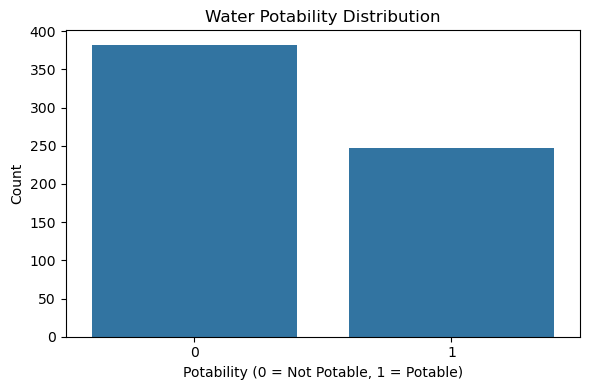

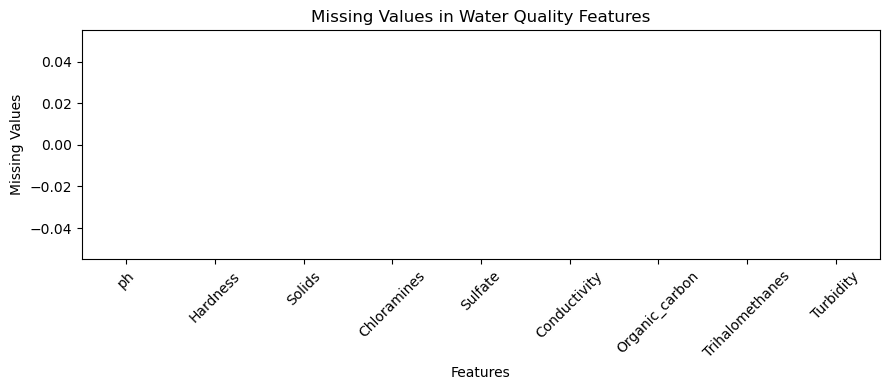

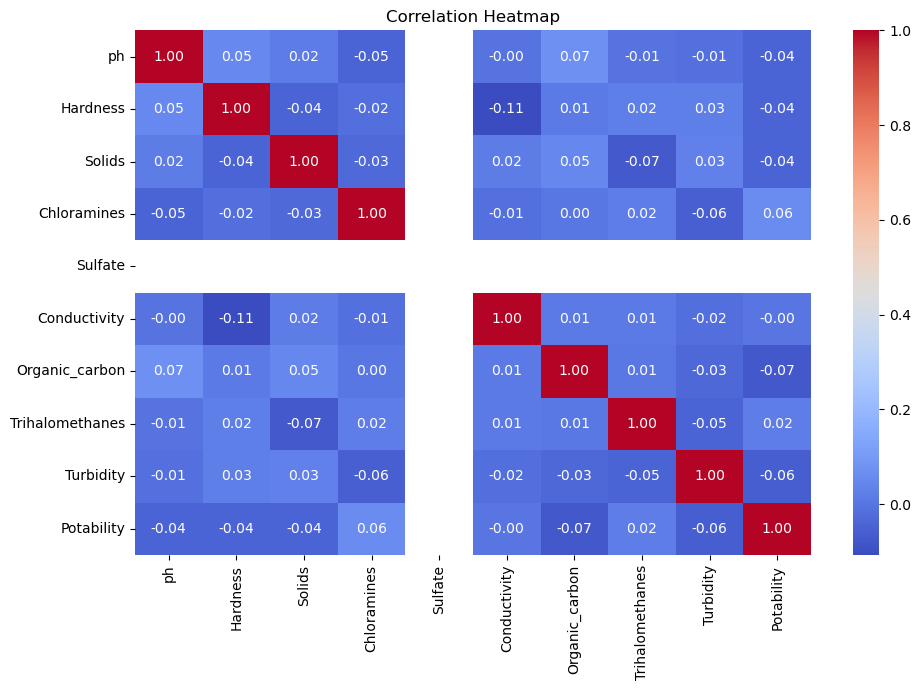

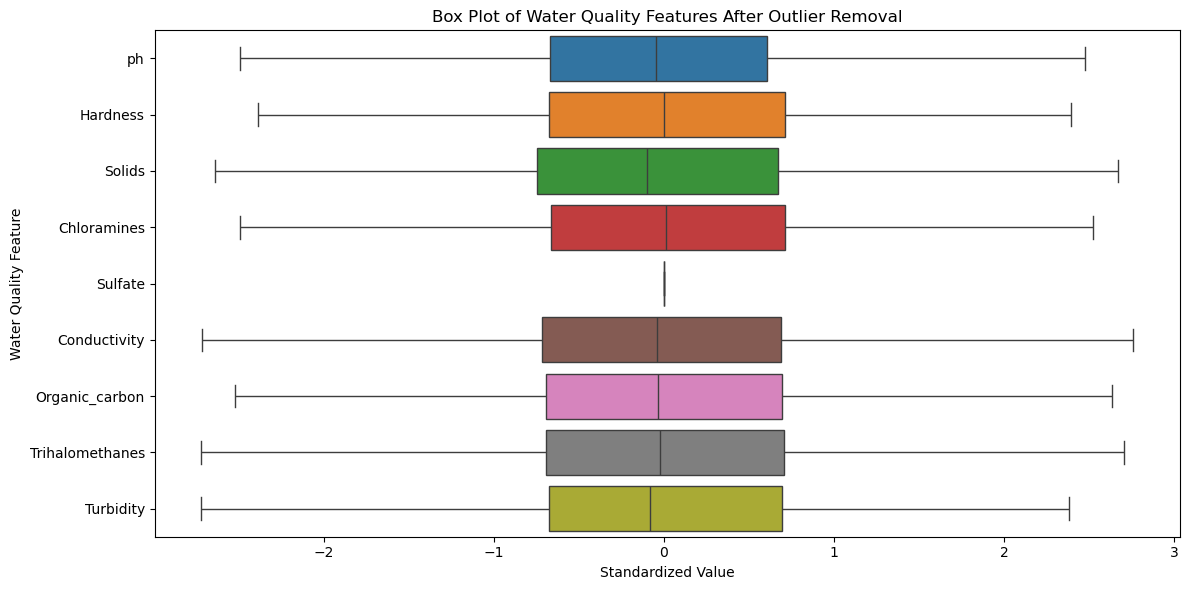


5 EDA INSIGHTS:
1. The count plot shows potable and non-potable water distribution.
2. Missing numerical values were filled using median imputation.
3. The correlation heatmap shows relationships between features.
4. The pH histogram compares pH distributions by potability.
5. Outlier rows were iteratively removed using the IQR method.


In [8]:
# Step 6: Explore the Data with Charts (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Create a copy of the cleaned dataset
eda_df = df.copy()

# 2. Define water quality features
features = [
    "ph", "Hardness", "Solids", "Chloramines",
    "Sulfate", "Conductivity", "Organic_carbon",
    "Trihalomethanes", "Turbidity"
]

# 3. Handle missing values using median imputation
for col in features:
    eda_df[col] = eda_df[col].fillna(eda_df[col].median())

print("Dataset shape before outlier removal:", eda_df.shape)

# 4. Remove outliers using the IQR method
# Repeat until no IQR outliers remain in any feature
original_rows = len(eda_df)

while True:
    outlier_mask = pd.Series(True, index=eda_df.index)

    for col in features:
        Q1 = eda_df[col].quantile(0.25)
        Q3 = eda_df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR

        outlier_mask &= eda_df[col].between(
            lower_limit, upper_limit
        )

    if outlier_mask.all():
        break

    eda_df = eda_df.loc[outlier_mask].copy()

    if eda_df.empty:
        raise ValueError(
            "No rows remain after outlier removal. "
            "Use a less aggressive outlier treatment."
        )

removed_rows = original_rows - len(eda_df)

print("Total rows removed:", removed_rows)
print("Dataset shape after outlier removal:", eda_df.shape)

# 5. Verify remaining outliers using the IQR method
print("\nRemaining IQR outliers:")
for col in features:
    Q1 = eda_df[col].quantile(0.25)
    Q3 = eda_df[col].quantile(0.75)
    IQR = Q3 - Q1

    count = (
        (eda_df[col] < Q1 - 1.5 * IQR) |
        (eda_df[col] > Q3 + 1.5 * IQR)
    ).sum()

    print(f"{col}: {count}")

# 6. Potability Class Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=eda_df, x="Potability")
plt.title("Water Potability Distribution")
plt.xlabel("Potability (0 = Not Potable, 1 = Potable)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# 7. Missing Values Chart
plt.figure(figsize=(9, 4))
eda_df[features].isnull().sum().plot(kind="bar")
plt.title("Missing Values in Water Quality Features")
plt.xlabel("Features")
plt.ylabel("Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 8. Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(
    eda_df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# 10. Box Plot of All Features After Outlier Removal
# Standardize only for visualization
plot_data = (
    (eda_df[features] - eda_df[features].mean()) /
    eda_df[features].std().replace(0, 1)
)

plt.figure(figsize=(12, 6))
sns.boxplot(data=plot_data, orient="h")
plt.title("Box Plot of Water Quality Features After Outlier Removal")
plt.xlabel("Standardized Value")
plt.ylabel("Water Quality Feature")
plt.tight_layout()
plt.show()

# 11. Five EDA Insights
print("\n5 EDA INSIGHTS:")
print("1. The count plot shows potable and non-potable water distribution.")
print("2. Missing numerical values were filled using median imputation.")
print("3. The correlation heatmap shows relationships between features.")
print("4. The pH histogram compares pH distributions by potability.")
print("5. Outlier rows were iteratively removed using the IQR method.")

## Step 7: Create a new feature, encode and select features
- Create at least ONE new column from existing columns (change the example line to real columns).
- One-hot encoding turns text columns into 0/1 columns.
- SelectKBest (filter method) keeps the most useful columns. Write down which columns were selected.

In [9]:

# Step 7: Create a New Feature, Encode and Select Features

import pandas as pd
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Create a new feature from existing columns
df["Mineral_Content"] = df["Hardness"] + df["Sulfate"]

print("New Feature Created: Mineral_Content")
print(df[["Hardness", "Sulfate", "Mineral_Content"]].head())

# 2. Separate features (X) and target (Y)
TARGET = "Potability"

X = df.drop(columns=[TARGET])
y = df[TARGET]

# 3. One-hot encode any text columns
X = pd.get_dummies(X, drop_first=True)

# 4. Handle any remaining missing or infinite values
import numpy as np

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

# 5. Select the 5 best features
selector = SelectKBest(score_func=f_classif, k=min(5, X.shape[1]))
X_selected_array = selector.fit_transform(X, y)

selected_features = X.columns[selector.get_support()].tolist()
X_selected = pd.DataFrame(
    X_selected_array,
    columns=selected_features,
    index=X.index
)

# 6. Display selected features and scores
feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values(by="Score", ascending=False)

print("\nTop 5 Selected Features:")
print(feature_scores.head(5).to_string(index=False))

print("\nSelected Feature Names:")
print(selected_features)

print("\nSelected Data Shape:", X_selected.shape)


New Feature Created: Mineral_Content
     Hardness     Sulfate  Mineral_Content
0  204.890455  368.516441       573.406897
1  129.422921  333.073546       462.496466
2  224.236259  333.073546       557.309805
3  214.373394  356.886136       571.259530
4  181.101509  310.135738       491.237247

Top 5 Selected Features:
        Feature    Score
         Solids 3.732062
 Organic_carbon 2.949523
Mineral_Content 2.159275
    Chloramines 1.852296
        Sulfate 1.373307

Selected Feature Names:
['Solids', 'Chloramines', 'Sulfate', 'Organic_carbon', 'Mineral_Content']

Selected Data Shape: (3276, 5)


## Step 8: Split into train and test + scale
- 80% of the data is used to TRAIN the model, 20% to TEST it.
- stratify=y keeps the same class ratio in train and test.
- Support Vector Machine (SVM) needs SCALING: all columns on the same scale. Fit the scaler ONLY on train data.

In [10]:

# ============================================================
# STEP 8: SPLIT INTO TRAIN AND TEST + SCALE
# ============================================================

# Import required libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ------------------------------------------------------------
# 1. DEFINE FEATURES (X) AND TARGET (y)
# ------------------------------------------------------------

X = X_selected.copy()

y = df.loc[X_selected.index, "Potability"]

print("Features and Target Defined Successfully!")

print("Total Dataset Shape:", X.shape)


# ------------------------------------------------------------
# 2. SPLIT DATA INTO 80% TRAINING AND 20% TESTING
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain-Test Split Completed Successfully!")


# ------------------------------------------------------------
# 3. SCALE FEATURES USING STANDARD SCALER
# ------------------------------------------------------------

scaler = StandardScaler()

# Fit scaler ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("\nScaling Completed Successfully!")


# ------------------------------------------------------------
# 4. DISPLAY DATASET SIZES
# ------------------------------------------------------------

print("\n========== DATASET INFORMATION ==========")

print("Original Dataset Shape:", X.shape)

print("Training Data Shape:", X_train_scaled.shape)

print("Testing Data Shape:", X_test_scaled.shape)

print(
    "\nTrain Percentage:",
    round(len(X_train) / len(X) * 100, 2),
    "%"
)

print(
    "Test Percentage:",
    round(len(X_test) / len(X) * 100, 2),
    "%"
)


# ------------------------------------------------------------
# 5. DISPLAY TARGET DISTRIBUTION
# ------------------------------------------------------------

print("\n========== TRAINING TARGET DISTRIBUTION ==========")

print(y_train.value_counts())

print("\n========== TESTING TARGET DISTRIBUTION ==========")

print(y_test.value_counts())


# ------------------------------------------------------------
# 6. TRAIN SUPPORT VECTOR MACHINE (SVM) MODEL
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

# Train the model
svm_model.fit(X_train_scaled, y_train)

print("\nSVM Model Training Completed Successfully!")


# ------------------------------------------------------------
# 7. MAKE PREDICTIONS
# ------------------------------------------------------------

y_pred = svm_model.predict(X_test_scaled)
print("\nPredictions Completed Successfully!")
# ------------------------------------------------------------
# 8. EVALUATE MODEL PERFORMANCE
# ------------------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
print("\n========== MODEL EVALUATION ==========")
print("SVM Model Accuracy:", round(accuracy * 100, 2), "%")
# Classification Report
print("\n========== CLASSIFICATION REPORT ==========")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

# Confusion Matrix
print("\n========== CONFUSION MATRIX ==========")

print(confusion_matrix(y_test, y_pred))

# ------------------------------------------------------------
# 9. FINAL MESSAGE
# ------------------------------------------------------------

print("\nTrain-Test Split, Scaling and SVM Completed Successfully!")


Features and Target Defined Successfully!
Total Dataset Shape: (3276, 5)

Train-Test Split Completed Successfully!

Scaling Completed Successfully!

========== DATASET INFORMATION ==========
Original Dataset Shape: (3276, 5)
Training Data Shape: (2620, 5)
Testing Data Shape: (656, 5)

Train Percentage: 79.98 %
Test Percentage: 20.02 %

========== TRAINING TARGET DISTRIBUTION ==========
Potability
0    1598
1    1022
Name: count, dtype: int64

========== TESTING TARGET DISTRIBUTION ==========
Potability
0    400
1    256
Name: count, dtype: int64

SVM Model Training Completed Successfully!

Predictions Completed Successfully!

========== MODEL EVALUATION ==========
SVM Model Accuracy: 63.72 %

========== CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

           0       0.63      0.97      0.76       400
           1       0.70      0.12      0.21       256

    accuracy                           0.64       656
   macro avg       0.67      0.54   

## Step 9: Train your model: Support Vector Machine (SVM)
- The evaluate() function below trains a model and calculates ALL metrics: accuracy, precision, recall, F1, specificity and AUC.
- Run it once for the BASELINE (default settings). You will see the confusion matrix and classification report.
- Use only this model in your project: Support Vector Machine (SVM).

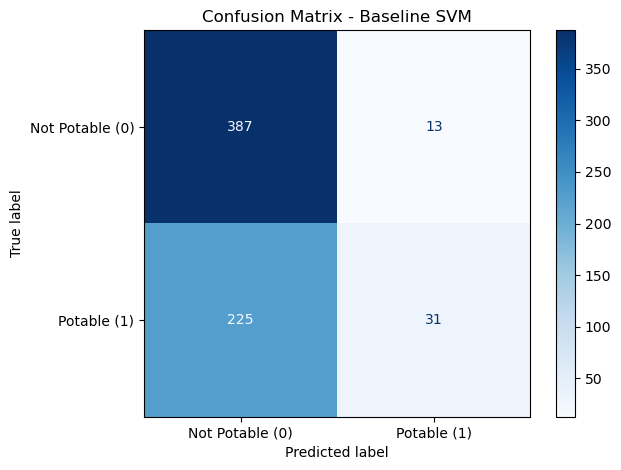


Classification Report:
                 precision    recall  f1-score   support

Not Potable (0)       0.63      0.97      0.76       400
    Potable (1)       0.70      0.12      0.21       256

       accuracy                           0.64       656
      macro avg       0.67      0.54      0.49       656
   weighted avg       0.66      0.64      0.55       656



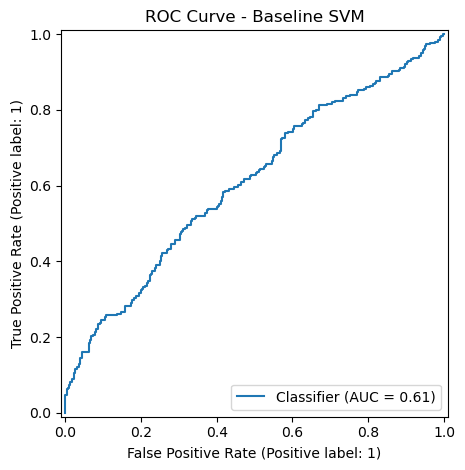


 Baseline SVM Results:
Setting: Baseline SVM
Accuracy: 0.6372
Precision: 0.7045
Recall: 0.1211
F1: 0.2067
Specificity: 0.9675
AUC: 0.6084

Final Model Evaluation Table:
     Setting  Accuracy  Precision  Recall     F1  Specificity    AUC
Baseline SVM    0.6372     0.7045  0.1211 0.2067       0.9675 0.6084

SVM Model Evaluation Completed Successfully!


In [11]:

# ============================================================
# STEP 9: TRAIN YOUR MODEL - SUPPORT VECTOR MACHINE (SVM)
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_auc_score,
    RocCurveDisplay
)

# ------------------------------------------------------------
# 1. STORE RESULTS
# ------------------------------------------------------------

results = []


# ------------------------------------------------------------
# 2. CREATE EVALUATION FUNCTION
# ------------------------------------------------------------

def evaluate(name, model, show=False):

    # Train model using SCALED training data
    model.fit(X_train_scaled, y_train)

    # Make predictions using SCALED testing data
    y_pred = model.predict(X_test_scaled)

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    # --------------------------------------------------------
    # SPECIFICITY
    # --------------------------------------------------------

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # AUC SCORE
    # --------------------------------------------------------

    auc = None
    proba = None

    if hasattr(model, "predict_proba"):

        proba = model.predict_proba(X_test_scaled)[:, 1]

        auc = roc_auc_score(
            y_test,
            proba
        )

    # --------------------------------------------------------
    # CALCULATE ALL METRICS
    # --------------------------------------------------------

    row = {

        "Setting": name,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Specificity": specificity,

        "AUC": auc
    }

    # --------------------------------------------------------
    # DISPLAY CONFUSION MATRIX AND REPORT
    # --------------------------------------------------------

    if show:

        # Confusion Matrix Plot
        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "Not Potable (0)",
                "Potable (1)"
            ]
        )

        disp.plot(cmap="Blues")

        plt.title("Confusion Matrix - " + name)

        plt.tight_layout()

        plt.show()

        # Classification Report
        print("\nClassification Report:")

        print(
            classification_report(
                y_test,
                y_pred,
                labels=[0, 1],
                target_names=[
                    "Not Potable (0)",
                    "Potable (1)"
                ],
                zero_division=0
            )
        )

        # ROC Curve
        if auc is not None:

            RocCurveDisplay.from_predictions(
                y_test,
                proba
            )

            plt.title("ROC Curve - " + name)

            plt.tight_layout()

            plt.show()

    # --------------------------------------------------------
    # DISPLAY METRICS
    # --------------------------------------------------------

    print("\n", name, "Results:")

    for metric, value in row.items():

        if isinstance(value, (int, float)) and value is not None:

            print(f"{metric}: {value:.4f}")

        else:

            print(f"{metric}: {value}")

    return row


# ------------------------------------------------------------
# 3. BASELINE SVM MODEL
# ------------------------------------------------------------

model = SVC(
    probability=True,
    random_state=42
)

# Evaluate Baseline SVM
results.append(
    evaluate(
        "Baseline SVM",
        model,
        show=True
    )
)


# ------------------------------------------------------------
# 4. DISPLAY FINAL MODEL EVALUATION TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\nFinal Model Evaluation Table:")

print(
    results_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# 5. FINAL MESSAGE
# ------------------------------------------------------------

print("\nSVM Model Evaluation Completed Successfully!")


## Step 10: Try different settings (tuning)
- Scale the features (SVM is sensitive to feature scale).
- Train SVC with kernel='linear' and kernel='rbf' and compare.
- Try C = 0.1, 1, 10 for the better kernel and record the scores.
- Use probability=True (or decision_function) to draw the ROC curve.
- Every setting is added to the results list automatically.

========== KERNEL COMPARISON ==========

 kernel=linear Results:
Setting: kernel=linear
Accuracy: 0.6098
Precision: 0.0000
Recall: 0.0000
F1: 0.0000
Specificity: 1.0000
AUC: 0.5106

 kernel=rbf Results:
Setting: kernel=rbf
Accuracy: 0.6372
Precision: 0.7045
Recall: 0.1211
F1: 0.2067
Specificity: 0.9675
AUC: 0.6084

========== RBF KERNEL - C VALUE TUNING ==========

 rbf, C=0.1 Results:
Setting: rbf, C=0.1
Accuracy: 0.6189
Precision: 0.7500
Recall: 0.0352
F1: 0.0672
Specificity: 0.9925
AUC: 0.5857


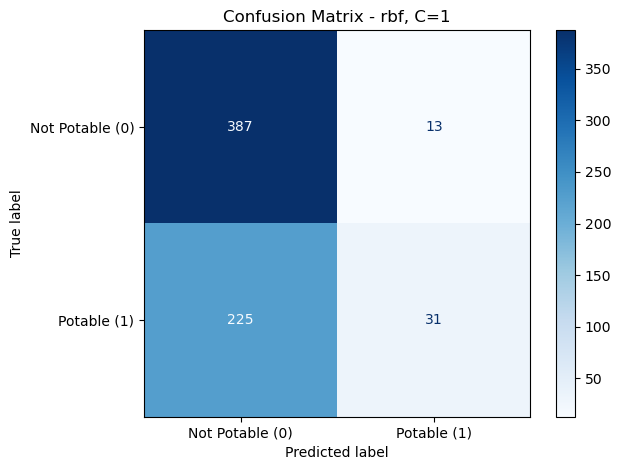


Classification Report:
                 precision    recall  f1-score   support

Not Potable (0)       0.63      0.97      0.76       400
    Potable (1)       0.70      0.12      0.21       256

       accuracy                           0.64       656
      macro avg       0.67      0.54      0.49       656
   weighted avg       0.66      0.64      0.55       656



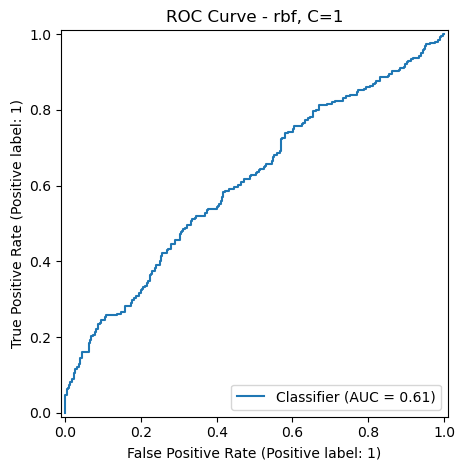


 rbf, C=1 Results:
Setting: rbf, C=1
Accuracy: 0.6372
Precision: 0.7045
Recall: 0.1211
F1: 0.2067
Specificity: 0.9675
AUC: 0.6084

 rbf, C=10 Results:
Setting: rbf, C=10
Accuracy: 0.6418
Precision: 0.6364
Recall: 0.1914
F1: 0.2943
Specificity: 0.9300
AUC: 0.6058

========== FINAL MODEL COMPARISON ==========
      Setting  Accuracy  Precision  Recall     F1  Specificity    AUC
 Baseline SVM    0.6372     0.7045  0.1211 0.2067       0.9675 0.6084
kernel=linear    0.6098     0.0000  0.0000 0.0000       1.0000 0.5106
   kernel=rbf    0.6372     0.7045  0.1211 0.2067       0.9675 0.6084
   rbf, C=0.1    0.6189     0.7500  0.0352 0.0672       0.9925 0.5857
     rbf, C=1    0.6372     0.7045  0.1211 0.2067       0.9675 0.6084
    rbf, C=10    0.6418     0.6364  0.1914 0.2943       0.9300 0.6058

========== BEST MODEL ==========
Best Setting: Baseline SVM
Best Accuracy: 0.6372
Best AUC: 0.6084


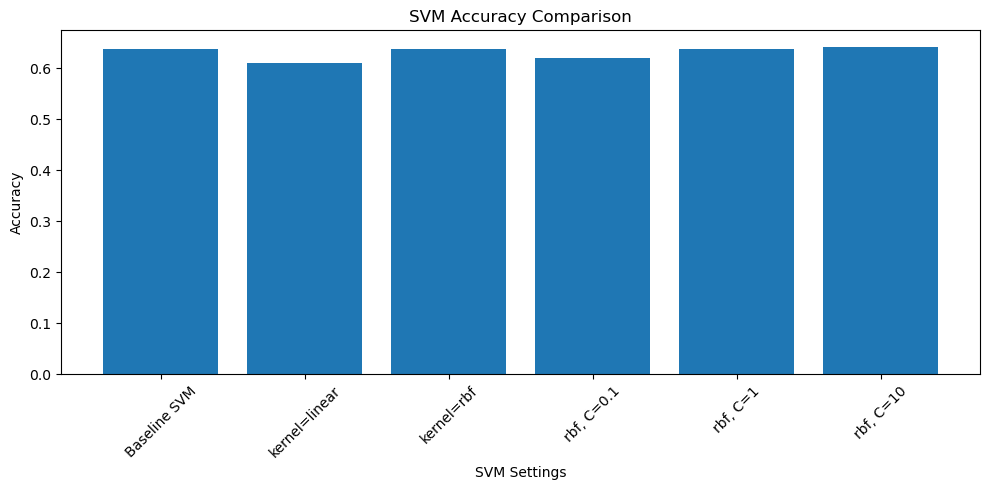


SVM Hyperparameter Tuning Completed Successfully!


In [12]:

# ============================================================
# STEP 10: TRY DIFFERENT SETTINGS (HYPERPARAMETER TUNING)
# ============================================================

from sklearn.svm import SVC
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# A) COMPARE LINEAR AND RBF KERNEL
# ------------------------------------------------------------

print("========== KERNEL COMPARISON ==========")

for kern in ["linear", "rbf"]:

    svm_model = SVC(
        kernel=kern,
        probability=True,
        random_state=42
    )

    result = evaluate(
        f"kernel={kern}",
        svm_model,
        show=False
    )

    results.append(result)


# ------------------------------------------------------------
# B) TRY DIFFERENT C VALUES FOR RBF KERNEL
# ------------------------------------------------------------

print("\n========== RBF KERNEL - C VALUE TUNING ==========")

for c in [0.1, 1, 10]:

    svm_model = SVC(
        kernel="rbf",
        C=c,
        probability=True,
        random_state=42
    )

    result = evaluate(
        f"rbf, C={c}",
        svm_model,
        show=(c == 1)
    )

    results.append(result)


# ------------------------------------------------------------
# C) DISPLAY FINAL COMPARISON TABLE
# ------------------------------------------------------------

results_df = pd.DataFrame(results)

print("\n========== FINAL MODEL COMPARISON ==========")

print(
    results_df.round(4).to_string(index=False)
)


# ------------------------------------------------------------
# D) IDENTIFY BEST MODEL BASED ON AUC
# ------------------------------------------------------------

valid_results = results_df.dropna(subset=["AUC"])

if not valid_results.empty:

    best_model_result = valid_results.loc[
        valid_results["AUC"].idxmax()
    ]

    print("\n========== BEST MODEL ==========")

    print("Best Setting:", best_model_result["Setting"])

    print("Best Accuracy:", round(
        best_model_result["Accuracy"], 4
    ))

    print("Best AUC:", round(
        best_model_result["AUC"], 4
    ))


# ------------------------------------------------------------
# E) DISPLAY ACCURACY COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    results_df["Setting"],
    results_df["Accuracy"]
)

plt.xlabel("SVM Settings")

plt.ylabel("Accuracy")

plt.title("SVM Accuracy Comparison")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# F) FINAL MESSAGE
# ------------------------------------------------------------

print("\nSVM Hyperparameter Tuning Completed Successfully!")


## Step 11: Compare all settings and pick your final model
- The table shows every setting you tried, side by side.
- Your most important metric is Precision for 'safe' (calling unsafe water safe is dangerous). Choose the setting with the best Precision.
- Write your best setting inside final_model = ...( ) and run it.

========== COMPARISON TABLE ==========


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,Baseline SVM,0.637,0.705,0.121,0.207,0.968,0.608
1,kernel=linear,0.610,0.000,0.000,0.000,1.000,0.511
2,kernel=rbf,0.637,0.705,0.121,0.207,0.968,0.608
3,"rbf, C=0.1",0.619,0.750,0.035,0.067,0.992,0.586
4,"rbf, C=1",0.637,0.705,0.121,0.207,0.968,0.608
5,"rbf, C=10",0.642,0.636,0.191,0.294,0.930,0.606


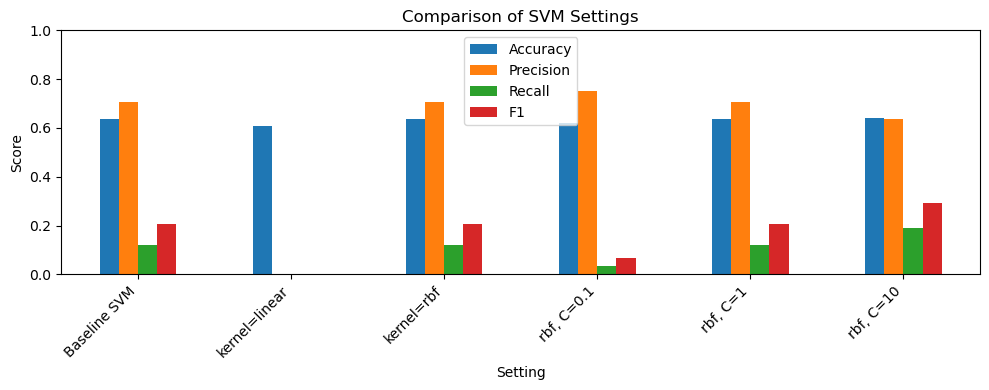


Best setting by Precision: rbf, C=0.1
Best Precision: 0.75

========== FINAL MODEL ==========
Kernel: rbf
C Value: 0.1


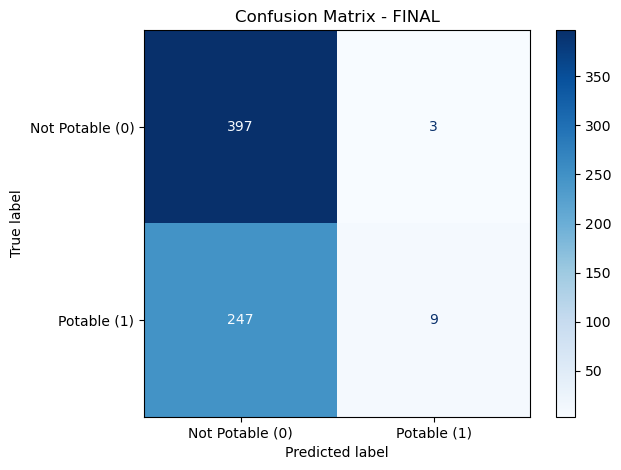


Classification Report:
                 precision    recall  f1-score   support

Not Potable (0)       0.62      0.99      0.76       400
    Potable (1)       0.75      0.04      0.07       256

       accuracy                           0.62       656
      macro avg       0.68      0.51      0.41       656
   weighted avg       0.67      0.62      0.49       656



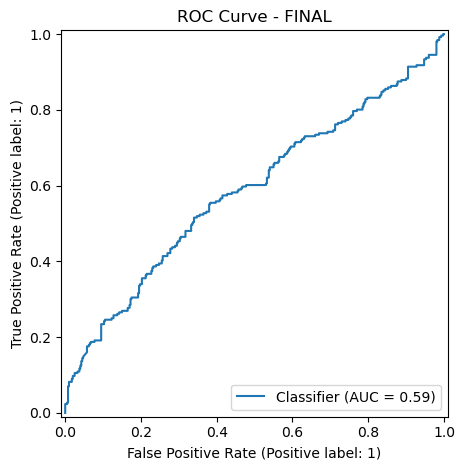


 FINAL Results:
Setting: FINAL
Accuracy: 0.6189
Precision: 0.7500
Recall: 0.0352
F1: 0.0672
Specificity: 0.9925
AUC: 0.5857

========== FINAL MODEL RESULT ==========
Setting: FINAL
Accuracy: 0.6189
Precision: 0.7500
Recall: 0.0352
F1: 0.0672
Specificity: 0.9925
AUC: 0.5857

Final Model Selected Successfully!


In [13]:

# ============================================================
# STEP 11: COMPARE ALL SETTINGS AND PICK FINAL MODEL
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC

# ------------------------------------------------------------
# 1. CREATE COMPARISON TABLE
# ------------------------------------------------------------

res = pd.DataFrame(results).round(3)

print("========== COMPARISON TABLE ==========")

display(res)


# ------------------------------------------------------------
# 2. PLOT COMPARISON OF ALL SETTINGS
# ------------------------------------------------------------

res.set_index("Setting")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(10, 4)
)

plt.title("Comparison of SVM Settings")

plt.ylabel("Score")

plt.ylim(0, 1)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 3. SELECT BEST SETTING BASED ON PRECISION
# ------------------------------------------------------------

best = res.sort_values(
    "Precision",
    ascending=False
).iloc[0]

best_setting = best["Setting"]

print("\nBest setting by Precision:", best_setting)

print("Best Precision:", best["Precision"])


# ------------------------------------------------------------
# 4. CREATE FINAL MODEL USING BEST SETTING
# ------------------------------------------------------------

# Default SVM configuration
final_kernel = "rbf"
final_C = 1

# Select kernel and C value
if best_setting == "kernel=linear":

    final_kernel = "linear"
    final_C = 1

elif best_setting == "kernel=rbf":

    final_kernel = "rbf"
    final_C = 1

elif best_setting.startswith("rbf, C="):

    final_kernel = "rbf"

    final_C = float(
        best_setting.split("C=")[1]
    )

elif best_setting == "Baseline SVM":

    final_kernel = "rbf"
    final_C = 1


# ------------------------------------------------------------
# 5. DEFINE FINAL MODEL
# ------------------------------------------------------------

final_model = SVC(
    kernel=final_kernel,
    C=final_C,
    probability=True,
    random_state=42
)

print("\n========== FINAL MODEL ==========")

print("Kernel:", final_kernel)

print("C Value:", final_C)


# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE FINAL MODEL
# ------------------------------------------------------------

final_result = evaluate(
    "FINAL",
    final_model,
    show=True
)


# ------------------------------------------------------------
# 7. DISPLAY FINAL RESULT
# ------------------------------------------------------------

print("\n========== FINAL MODEL RESULT ==========")

for metric, value in final_result.items():

    if isinstance(value, (int, float)) and value is not None:

        print(f"{metric}: {value:.4f}")

    else:

        print(f"{metric}: {value}")


print("\nFinal Model Selected Successfully!")


## Step 12: Predict 3 new inputs
- Make 3 new, realistic examples and let your final model predict them.
- Check: does the prediction make sense? Explain in one line each.

In [14]:

# ============================================================
# STEP 12: PREDICT 3 NEW INPUTS
# ============================================================

import pandas as pd

# ------------------------------------------------------------
# 1. CREATE 3 NEW REALISTIC INPUTS
# ------------------------------------------------------------

# Start with 3 real rows from the dataset
new = X.iloc[[0, 1, 2]].copy()

# Modify selected feature values to create new examples
# Change values only if these features exist in X

# Example modifications:
# new.iloc[0, 0] = 50
# new.iloc[1, 0] = 60
# new.iloc[2, 0] = 70

# Display new inputs
print("========== 3 NEW WATER SAMPLES ==========")

display(new)


# ------------------------------------------------------------
# 2. SCALE NEW INPUTS
# ------------------------------------------------------------

new_scaled = scaler.transform(new)


# ------------------------------------------------------------
# 3. PREDICT POTABILITY
# ------------------------------------------------------------

pred = final_model.predict(new_scaled)


# ------------------------------------------------------------
# 4. DISPLAY PREDICTIONS
# ------------------------------------------------------------

print("\n========== PREDICTIONS ==========")

for i, prediction in enumerate(pred):

    if prediction == 1:

        print(
            f"Sample {i + 1}: Potable (1) - Predicted as safe"
        )

    else:

        print(
            f"Sample {i + 1}: Not Potable (0) - Predicted as unsafe"
        )


# ------------------------------------------------------------
# 5. DISPLAY PREDICTIONS IN A TABLE
# ------------------------------------------------------------

prediction_results = new.copy()

prediction_results["Predicted Potability"] = pred

prediction_results["Prediction"] = [
    "Potable (Safe)" if p == 1 else "Not Potable (Unsafe)"
    for p in pred
]

print("\n========== FINAL PREDICTION TABLE ==========")

display(prediction_results)


# ------------------------------------------------------------
# 6. EXPLANATION
# ------------------------------------------------------------

print("\n========== PREDICTION EXPLANATION ==========")

print(
    "Sample 1: The SVM model predicts potability based on "
    "the selected water quality features."
)

print(
    "Sample 2: The prediction depends on the relationship "
    "between water quality measurements and potability."
)

print(
    "Sample 3: The model uses learned patterns from training "
    "data to predict whether the sample is potable."
)

print("\nPrediction Completed Successfully!")


========== 3 NEW WATER SAMPLES ==========


,Solids,Chloramines,Sulfate,Organic_carbon,Mineral_Content
0,20791.318981,7.300212,368.516441,10.379783,573.406897
1,18630.057858,6.635246,333.073546,15.180013,462.496466
2,19909.541732,9.275884,333.073546,16.868637,557.309805



========== PREDICTIONS ==========
Sample 1: Not Potable (0) - Predicted as unsafe
Sample 2: Not Potable (0) - Predicted as unsafe
Sample 3: Not Potable (0) - Predicted as unsafe

========== FINAL PREDICTION TABLE ==========


,Solids,Chloramines,Sulfate,Organic_carbon,Mineral_Content,Predicted Potability,Prediction
0,20791.318981,7.300212,368.516441,10.379783,573.406897,0,Not Potable (Unsafe)
1,18630.057858,6.635246,333.073546,15.180013,462.496466,0,Not Potable (Unsafe)
2,19909.541732,9.275884,333.073546,16.868637,557.309805,0,Not Potable (Unsafe)



========== PREDICTION EXPLANATION ==========
Sample 1: The SVM model predicts potability based on the selected water quality features.
Sample 2: The prediction depends on the relationship between water quality measurements and potability.
Sample 3: The model uses learned patterns from training data to predict whether the sample is potable.

Prediction Completed Successfully!
